# 动态环境中的鲁棒定位与 SLAM：实验逐步展示
**朱子霖 · 2026-10-14 · 本机证据版本**

我的大方向是 **Robust localization and SLAM in dynamic environments**。今天先展示原库复现，再展示同一机器人上逐步增加压力的建图与定位测试，最后用观察结果讨论开放问题。

**开放问题：在退化与大变动环境中，什么样的策略能够有效地让定位系统自恢复？**

这是一组已执行的基线实验与问题分析。目前没有提出并验证新的自恢复算法。

## 展示路线

1. [问题与机器人](#question)：说明动态、退化和地图变化分别影响什么。
2. [作者原库实验](#authors)：DUFOMap → BeautyMap → IR-MCL → AdaM-MCL，保留各自指标。
3. [静态基线](#static)：建图 A → 生成三张地图 → 独立定位 B → 复算误差。
4. [动态环境](#dynamic)：运动障碍与六个同时运行的定位对照。
5. [持久结构变化](#change)：旧地图遇到新结构，检查是否真的失效。
6. [走廊退化与观测恢复](#degradation)：受限扫描、恢复事件、连续更新和持续收敛。
7. [收窄问题](#narrow)：提出可证伪的下一轮实验，而不是提前选定方法。

**操作**：双击同目录 `一键打开Notebook.bat`；按 **Shift+Enter** 逐格运行，或只讲解已保存的输出。视频点播放即可，全长 MP4 也可单独打开。左侧目录可跳转章节。

现场启动单元默认 `False`，仅在要现场演示时，把该单元改成 `True` 后单独运行。全部运行会复算保存的数据，不会自动启动八场实验。离线 HTML 适合直接讲解，不需要内核。

In [1]:
import numpy as np
from IPython.display import HTML, display
from experiment_tools import (
    DATA, REPO, PACKAGES, package, table, videos, verify_files,
    samples, score_table, trajectory_plot, map_comparison, mapping_info,
    degradation_analysis, author_lidar, ir_analysis, adam_analysis, launch,
)
display(HTML("""<style>
.experiment-table {border-collapse:collapse; font-size:15px; margin:14px 0;}
.experiment-table th,.experiment-table td {padding:9px 12px;border:1px solid #ddd;text-align:left;}
.experiment-table th {background:#edf2f7;}
</style>"""))
print("证据目录：", DATA)
print("现场入口仓库：", REPO)
assert all((package(n) / "record.json").is_file() for n in PACKAGES)
print("11 个冻结实验包齐全。Notebook 分析不依赖 ROS、Gazebo 或 PyTorch 内核。")

证据目录： D:\workspace\be2\slam_learning_updated\results\reference
现场入口仓库： D:\workspace\be2\slam_learning_updated
11 个冻结实验包齐全。Notebook 分析不依赖 ROS、Gazebo 或 PyTorch 内核。


### 先核对证据
每个包保存现场录像、结果回放、参数、日志和数据。下面逐文件检查记录中的字节数与 SHA-256；后续还会用原生 CSV / TUM 轨迹重新计算指标。

便携展示目录包含这 11 个发布包；大体积原始 ROS bag 与三维点云输入仍在本机 `results/runs/presentation`。可以展示已保留的结果，完整重跑仍使用本机环境和原始数据。

In [2]:
verified_artifacts = verify_files()

实验包,状态,核对文件,结果
robot-static-mapping,executed,17,SHA-256 一致
robot-static,executed,36,SHA-256 一致
robot-dynamic-mapping,executed,17,SHA-256 一致
robot-dynamic,executed,51,SHA-256 一致
robot-large-change,executed,37,SHA-256 一致
robot-corridor-mapping,executed,20,SHA-256 一致
robot-degradation,executed,56,SHA-256 一致
desktop-dufomap,executed,15,SHA-256 一致
desktop-beautymap,executed,16,SHA-256 一致
desktop-ir-mcl,executed,16,SHA-256 一致


共核对 296 个记录绑定文件；大体积 ROS bag / 点云源文件仍保留在本机原始运行目录。


<a id="question"></a>
## 1. 开放问题为什么有道理，为什么还太宽

动态目标可能污染地图或当前观测；退化几何使某些运动方向约束变弱；持久变化使历史地图失配。这三种机制并不等价，不能用一次定位误差横排所有论文。

| 概念 | 需要观察什么 | 不能直接等同于 |
|---|---|---|
| 动态鲁棒性 | 当前观测中的运动目标、地图污染、估计误差 | 过滤掉的点越多越好 |
| 几何 / 感知退化 | 约束不足、扫描范围、更新触发、方向性误差 | 所有退化都能靠动态过滤解决 |
| 持久结构变化 | 历史地图与当前稳定结构不一致 | 看到新障碍就代表定位丢失 |
| 自恢复 | 已失效后重新达到可确认的定位质量 | 初值很好时继续跟踪成功 |

原问题有应用动机，但同时涵盖检测、归因、恢复动作和恢复确认，跨度很大。这里把它作为**大方向下的问题地图**；用实验查出可重复失败与恢复条件，再选一个边界收窄。

**讲述**：我此前把地图清理和语义规划放在同一个位姿误差表里，指标与下游不一致。现在把研究主线固定到动态环境中的鲁棒定位与 SLAM，原库复现和平台测试各自说明协议。

### 机器人、传感器与数据流

底盘来自 [Sim2Real-AlgoBench](https://github.com/p20030920p/Sim2Real-AlgoBench)，固定来源提交 `53324d40def0dd753b4a99021b8fe596955a1ecd`。保留三轮全向底盘和原生二维传感器，新增独立三维激光版本。

| 层 | 配置 | 当前验证范围 |
|---|---|---|
| 原生二维 | 720 束，360°，0.08–12 m，配置 10 Hz；RGB 相机 640×480 | slam_toolbox 在线建图；Nav2 AMCL 定位 |
| 独立三维 | 720×16，垂直 ±15°，0.08–12 m，配置 10 Hz，/points | 使用给定位姿的点云建图与作者地图过滤 |
| 走廊压力输入 | 从同一二维扫描派生 72 束、240°、3.5 m，随后恢复原始扫描 | 与完整观测同时对照；不加人工噪声 |
| 实体机器人 | 同底盘，二维 / 三维分层 | 待测 |

```text
建图 A：二维 scan → slam_toolbox → 在线二维地图（现场 RViz）
        三维 points + 给定传感器位姿 → Raw / DUFOMap / BeautyMap → 固定二维地图
独立 B：同一二维 scan + 轮速里程计 → 多个相同 AMCL（只换地图 / 扫描条件）
评分：  Gazebo 独立模型真值 ─────→ 时间关联 → CSV → RMSE / 持续收敛
```

**真值不给定位器 B，也不给巡航控制器。** A 使用真值位姿控制地图构建误差，因此这一步是三维建图实验，不能声称完成三维 SLAM。新增点云没有逐点时间字段，逐点运动畸变评测尚未完成。配置频率不等于实际算法吞吐。

本机现场是实际 Windows Gazebo、RViz 和终端窗口；D3D12 NVIDIA 加速与 RViz 采样器补丁已生效。历史离屏 `map_view.py` 是自建看图程序，不能冒充本轮 RViz。

<a id="authors"></a>
## 2. 作者原库实验：先确认每种工作的输入、输出和指标

下列四项均保留新的作者代码执行记录和本次结果回放。它们不是同一个定位系统里的四个可替换前端：地图清理指标与定位指标分开报告。

### 2.1 DUFOMap
**问题**：在多次点云观测中保留稳定结构，去除动态残留。输入是发布的 KITTI-00 141 帧点云与给定位姿，输出是清理后的地图。

**展示顺序**：先看原库命令行执行，再看输出点云环视。环视只展示最终地图，不能解释成在线建图增长。

In [3]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("dufomap", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original.ps1 -Method dufomap -RepoRoot D:\workspace\be2\slam_learning_updated -Trials 1


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

In [4]:
videos("desktop-dufomap")

**指标**：SA = 保留静态 / 全部静态；DA = 删除动态 / 全部动态；HA 为二者调和平均。下面重算保存的计数比率。计数来自 0.05 m 阈值的独立 SciPy 近邻评分器，本轮没有重新进行 PCL 交叉核验；不把这个分数当作定位误差。

In [5]:
author_lidar("desktop-dufomap")

量,独立评分器的已保存计数
kept_static,16917434
removed_static,348813
removed_dynamic,94738
kept_dynamic,1245


SA (%),DA (%),HA (%),近邻距离阈值(m)
97.9798,98.7029,98.3400,0.05


这里重算计数的比率；不重载大体积 PCD 做近邻搜索，不声称本轮 PCL 交叉核验。


**当前结论**：原库流程与清理输出已执行。动态残留清理是否改善定位，要在后面的同机器人定位 B 中检验；地图质量分数本身不能回答。

### 2.2 BeautyMap
**问题**：通过作者地图清理规则得到更稳定的参考地图。本轮同样使用 KITTI-00 141 帧，和历史论文表中 KITTI-02 的复现范围分开。

In [6]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("beautymap", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original.ps1 -Method beautymap -RepoRoot D:\workspace\be2\slam_learning_updated -Trials 1


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

In [7]:
videos("desktop-beautymap")
author_lidar("desktop-beautymap")

量,独立评分器的已保存计数
kept_static,16740135
removed_static,526112
removed_dynamic,94388
kept_dynamic,1595


SA (%),DA (%),HA (%),近邻距离阈值(m)
96.9529,98.3382,97.6407,0.05


这里重算计数的比率；不重载大体积 PCD 做近邻搜索，不声称本轮 PCL 交叉核验。


**当前结论**：本次原库处理和结果已保留。后面的室内平台适配还需要单独披露：小地图索引越界通过工作 XY 索引加边界修正，原始世界坐标不变；不能把平台参数下的点数当论文 SA/DA。

### 2.3 IR-MCL
**问题**：作者神经占据场为粒子生成预测扫描，用观测一致性进行全局定位。

官方公开 Bonn IPBLab Seq 1 共处理 1543 帧，原协议排除开始约 20 秒后，在 1354 帧窗口评分。使用发布权重和原生配置；C++ 扩展使用兼容的 pybind11，两行 Python 兼容修改已保留。

In [8]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("ir-mcl", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original.ps1 -Method ir-mcl -RepoRoot D:\workspace\be2\slam_learning_updated -Trials 1


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

In [9]:
videos("desktop-ir-mcl")

下面直接读取作者 `IRMCL.txt` 与发布真值 TUM 轨迹，复算八项指标，不作空间对齐。

论文 §IV-B Seq 1 / IR-MCL 的同范围为 **5.13 cm / 1.05°**；本次新的推理为 **5.36 cm / 1.06°**。历史另一次本机执行是 5.32 cm / 1.07°，不能把不同运行混成同一条录像。原生随机运动模型导致重复结果可能变化。

指标,本次原生轨迹复算
location_rmse_cm,5.36
yaw_rmse_deg,1.06
location_lt5_pct,63.52
location_lt10_pct,95.49
location_lt20_pct,100.0
yaw_lt0_5_pct,47.49
yaw_lt1_pct,75.92
yaw_lt2_pct,93.5


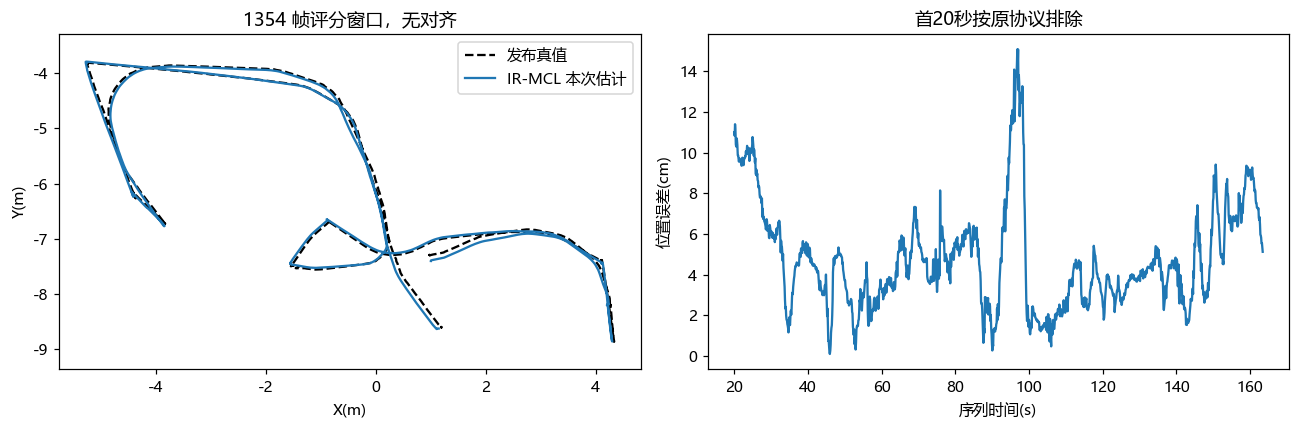

In [10]:
ir_analysis()

**当前结论**：完成该公开序列的作者定位流程与数值复算。当前没有把 IR-MCL 接入 Gazebo 动态 / 退化实验，也没有验证它在本开放问题下的自恢复效果。

### 2.4 AdaM-MCL
**问题**：运行作者的自适应混合粒子定位流程，观察全局定位与绑架后的表现。

作者固定库里的数据 / 权重目录为空，外部数据未获取。本次使用自建 128 格地图与作者自己的生成器，DSOM 已训练 **2432 步**，远小于作者默认 **2,880,000 步**。这属于受限条件下的作者流程执行，不能称作完整论文指标复现。

In [11]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("adam-mcl", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original.ps1 -Method adam-mcl -RepoRoot D:\workspace\be2\slam_learning_updated -Trials 1


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

原生日志最大真值跳变：索引 63（从0计），即第 64 次更新（从1计）。


项,本轮复算
RMSE (cells),32.227531
末次误差 (cells),34.408260
更新数,123
平均更新耗时(s),0.431966


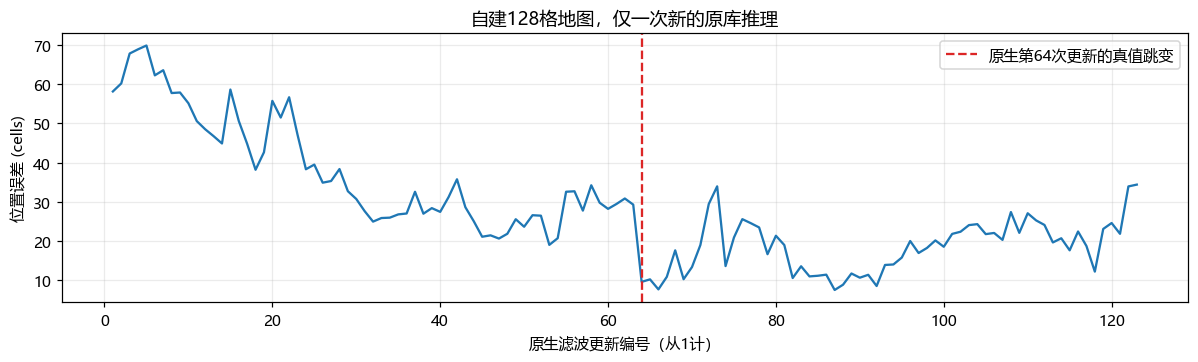

历史10次结果更正,正确统计
平均逐次 RMSE (cells),34.822406
平均末次误差 (cells),47.711511
满足持续全局/绑架收敛,0/10；0/10


In [12]:
videos("desktop-adam-mcl")
adam_analysis()

**当前结论**：新的 123 更新、一次推理，RMSE **32.23 cells**、末误差 **34.41 cells**。单位是格，不是米；没有证明绑架后成功恢复。

**评分更正**：作者 `error_position.txt` 已经保存欧氏距离，正确 RMSE 是 `sqrt(mean(distance**2))`。历史包装器曾再次开平方，得到错误的 5.49 cells 等数值，这些已撤回；原始证据字节保留，10 次记录的更正见上表。现场原生图里的旧 footer 不作评分依据。

**可以对老师说明**：目前最完整的是 IR-MCL 公开定位序列；AdaM-MCL 的数据与训练仍有限，必须补齐条件后才能谈论文结论。

## 3. 平台测试的统一流程与评分

每种场景先完成建图 A，保存三维点云；用 Raw、DUFOMap、BeautyMap 得到三张二维定位地图。再启用独立仿真 B，同时运行参数相同的 AMCL。地图处理、定位和评分是三步。

| 控制项 | 本轮做法 |
|---|---|
| 点云建图 | A 每仿真秒一帧，均匀选最多 60 帧；给定传感器位姿 |
| 地图投影 | 同一真实扫描自由射线、0.12–1.20 m 高度带、0.05 m 栅格、一格占据膨胀 |
| DUFOMap | 0.1 m；d_s=0.2，d_p=1 |
| BeautyMap | range=8 m；XY=0.5 m；Z=0.2 m；室内索引适配补丁留档 |
| B 定位器 | 原生 Nav2 AMCL，OmniMotionModel，500–2000 粒子，最多 60 束，其他参数一致 |
| 独立真值 | Gazebo Pose_V / omni_car，消息顶层仿真时间戳，只评分与显示 |
| 时间匹配 | 每次原生 AMCL 更新匹配最近真值，差不超过 0.05 仿真秒 |
| 重复性 | 每种条件目前一次，同场景方法共用输入；不是多次独立统计显著性实验 |

### RMSE 从哪里来

每个 `<case>-samples.csv` 包含时间、估计 X/Y/yaw、真值 X/Y/yaw、最近真值时间差。

```python
distance = sqrt((estimate_x - truth_x)**2 + (estimate_y - truth_y)**2)
RMSE_xy = sqrt(mean(distance**2))
yaw_error = atan2(sin(estimate_yaw - truth_yaw), cos(estimate_yaw - truth_yaw))
RMSE_yaw = degrees(sqrt(mean(yaw_error**2)))
```

不作 SE(2) 对齐。全窗含初始化，另报各方法首条记录后 5 秒窗口；5 秒只是披露的评分口径，不代表系统已经收敛。评分包含录屏就绪之前的初始更新。

现场视频按**墙钟**采集三个真实窗口；结果回放按**仿真时间**重放已保存定位更新，不运行新的推理。时长不同可以成立。

**现场依赖顺序**：建图 A → `build-static/dynamic/corridor` → 定位 B。定位入口会优先取最新建图标记，没有新标记时使用发布地图。下面的分析始终读取冻结发布包，启动新实验不会改写这些表。

In [13]:
example = samples("robot-static", "raw")
table(["stamp(s)", "truth_x", "truth_y", "estimate_x", "estimate_y", "e_xy(m)", "Δt(s)"],
      [[round(float(row[k]), 6) for k in
        ("stamp_s", "truth_x", "truth_y", "estimate_x", "estimate_y", "position_error_m", "nearest_truth_delta_s")]
       for row in example[:5]])
distance = np.hypot(example["estimate_x"]-example["truth_x"], example["estimate_y"]-example["truth_y"])
print("手工复算 Raw 静态全窗 RMSE =", np.sqrt(np.mean(distance**2))*100, "cm")

stamp(s),truth_x,truth_y,estimate_x,estimate_y,e_xy(m),Δt(s)
5.0,8.0727,7.5312,8.3227,7.6812,0.291548,0.001
9.9,8.072678,7.5312,8.319395,7.67704,0.286598,0.005
10.0,8.072678,7.5312,8.317621,7.662045,0.277701,0.001
10.1,8.072678,7.5312,8.306071,7.643233,0.25889,0.001
10.2,8.072678,7.5312,8.303637,7.624516,0.249098,0.004


手工复算 Raw 静态全窗 RMSE = 7.082687844807128 cm


<a id="static"></a>
## 4. 实验 S1：纯静态基线

**实验问题**：没有运动目标时，底盘、传感器、TF、建图和定位链路能否正常工作？地图处理是否误删了有效结构？

**条件**：静态竞技场；相同底盘、原生 720 束二维扫描、独立三维扫描。定位初值偏移 X=0.25 m、Y=0.15 m、yaw=0.12 rad。A 和 B 分开运行。

### 步骤 A：建图现场
观察 Gazebo 机器人移动、RViz 真实地图 / 点云更新，以及终端收到的数据。打开手动实验后在专用终端使用键盘节点；自动驾驶重录可改 `auto=True, record=True`。

In [14]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("mapping-static", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\presentation.ps1 -Flow mapping-static -RepoRoot D:\workspace\be2\slam_learning_updated -Duration 0


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

In [15]:
videos("robot-static-mapping", result=False)
mapping_info("robot-static-mapping")

项目,本轮记录
三维点云消息,965
保存建图帧,97
在线二维地图,292 × 143
已知栅格数,22066
三维建图位姿,给定的 Gazebo 传感器位姿；不是三维 SLAM 产出


### 步骤 B：处理本次地图
下面入口处理最新静态建图，完成后再启动定位。图表展示已发布那次 A 的实际输出。

In [16]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("build-static", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\build-maps.ps1 -Scene static -RepoRoot D:\workspace\be2\slam_learning_updated


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

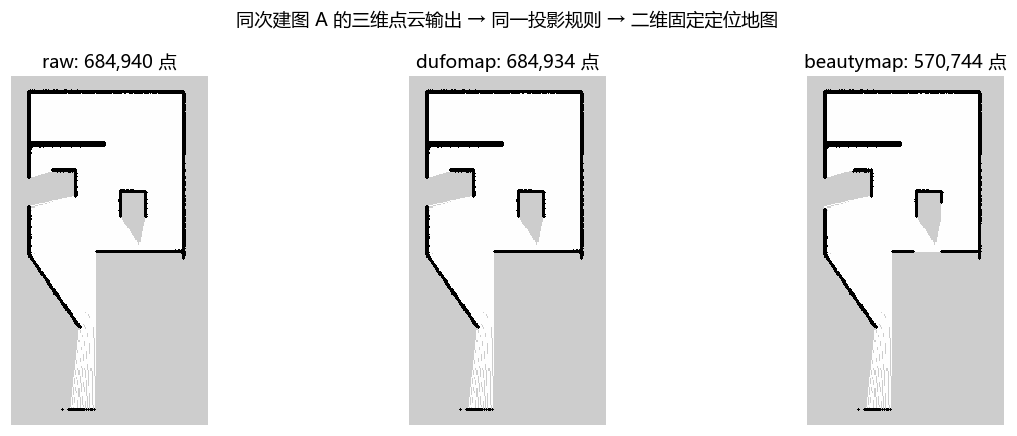

地图,输出点数,栅格 (m),PGM SHA-256 前16位
raw,684940,0.05,040efe320426e4a2
dufomap,684934,0.05,040efe320426e4a2
beautymap,570744,0.05,eb35c804e1bf86ba


点数只是处理输出规模；没有逐点静动态真值，不能换算静态误删率。


In [17]:
map_comparison("robot-static")

### 步骤 C：独立定位，复算误差
三组同时接收同一扫描与轮速里程计；RViz 显示 Raw 对应的机器人 TF，其他组见终端 / 结果回放。

In [18]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("localization-static", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\presentation.ps1 -Flow localization-static -RepoRoot D:\workspace\be2\slam_learning_updated -Duration 0


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

In [19]:
videos("robot-static")

地图 / 输入组,更新数,全窗 RMSE (cm),首条后 5s RMSE (cm),偏航 RMSE (°),位置 P95 (cm)
raw,290,7.083,6.687,1.014,9.485
dufomap,290,7.083,6.687,1.014,9.485
beautymap,290,6.549,6.114,1.155,8.491


由原生更新的估计与真值重新计算；最近真值时间差 ≤0.05 仿真秒；没有轨迹对齐。


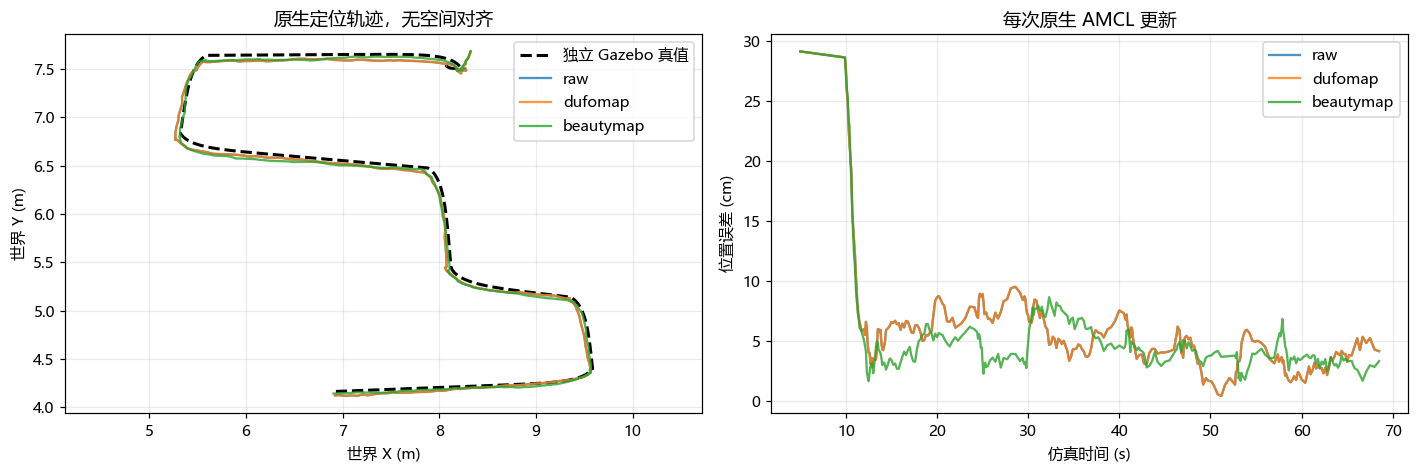

In [20]:
score_table("robot-static")
trajectory_plot("robot-static")

**观察**：全窗 Raw / DUFOMap 7.08 cm，BeautyMap 6.55 cm。Raw 与 DUFOMap 的二维地图相同，结果也相同。本轮没有诱发定位丢失。

**能回答**：整条链路能够运行，静态基线数值可复算。**暂不能回答**：单轮略小的 RMSE 是否代表方法普遍更优，或删除了多少正确静态点。

<a id="dynamic"></a>
## 5. 实验 S2：动态环境

**实验问题**：运动障碍出现在建图 A 与当前定位 B 时，地图清理与“直接使用静态地图”对照分别有什么影响？

**条件**：同竞技场增加三个脚本驱动的运动障碍。B 同时运行六组：动态 A 的 Raw / DUFOMap / BeautyMap，及静态 A 的 clean_raw / clean_dufomap / clean_beautymap；六组共享当前动态扫描与轮速。

### 步骤 A：动态点云建图与地图处理
先看障碍运动和实际地图变化，再查看三维处理输出。地图清理点数不是动态移除精度。

In [21]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("mapping-dynamic", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\presentation.ps1 -Flow mapping-dynamic -RepoRoot D:\workspace\be2\slam_learning_updated -Duration 0


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

In [22]:
videos("robot-dynamic-mapping", result=False)
mapping_info("robot-dynamic-mapping")

项目,本轮记录
三维点云消息,1001
保存建图帧,100
在线二维地图,293 × 143
已知栅格数,22001
三维建图位姿,给定的 Gazebo 传感器位姿；不是三维 SLAM 产出


In [23]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("build-dynamic", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\build-maps.ps1 -Scene dynamic -RepoRoot D:\workspace\be2\slam_learning_updated


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

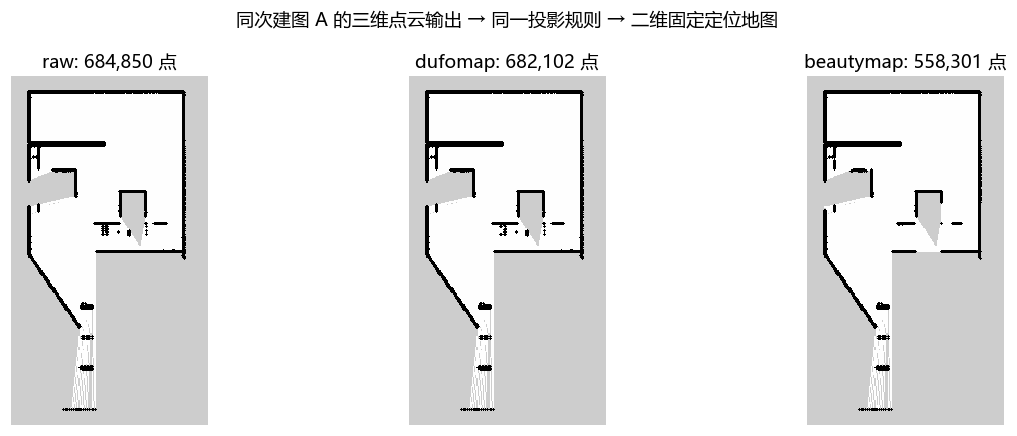

地图,输出点数,栅格 (m),PGM SHA-256 前16位
raw,684850,0.05,6815c43d6664f975
dufomap,682102,0.05,9a4df43df8cc482d
beautymap,558301,0.05,4f9c77776b4c48b4


点数只是处理输出规模；没有逐点静动态真值，不能换算静态误删率。


In [24]:
map_comparison("robot-dynamic")

### 步骤 B：相同动态输入上的六组定位
**观察重点**：障碍穿过视野时，当前误差是否升高；清理后的地图是否比静态地图控制组更好。不能通过跨场景 Raw 的微小差值直接归因于运动障碍，因为路线与地图不是完全相同的控制条件。

In [25]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("localization-dynamic", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\presentation.ps1 -Flow localization-dynamic -RepoRoot D:\workspace\be2\slam_learning_updated -Duration 0


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

In [26]:
videos("robot-dynamic")

地图 / 输入组,更新数,全窗 RMSE (cm),首条后 5s RMSE (cm),偏航 RMSE (°),位置 P95 (cm)
raw,291,7.312,5.932,1.302,8.897
dufomap,291,7.103,5.647,1.252,10.469
beautymap,291,7.278,5.626,1.228,9.460
clean_raw,291,6.305,4.530,1.258,6.731
clean_dufomap,291,6.305,4.530,1.258,6.731
clean_beautymap,291,6.894,5.431,1.235,8.941


由原生更新的估计与真值重新计算；最近真值时间差 ≤0.05 仿真秒；没有轨迹对齐。


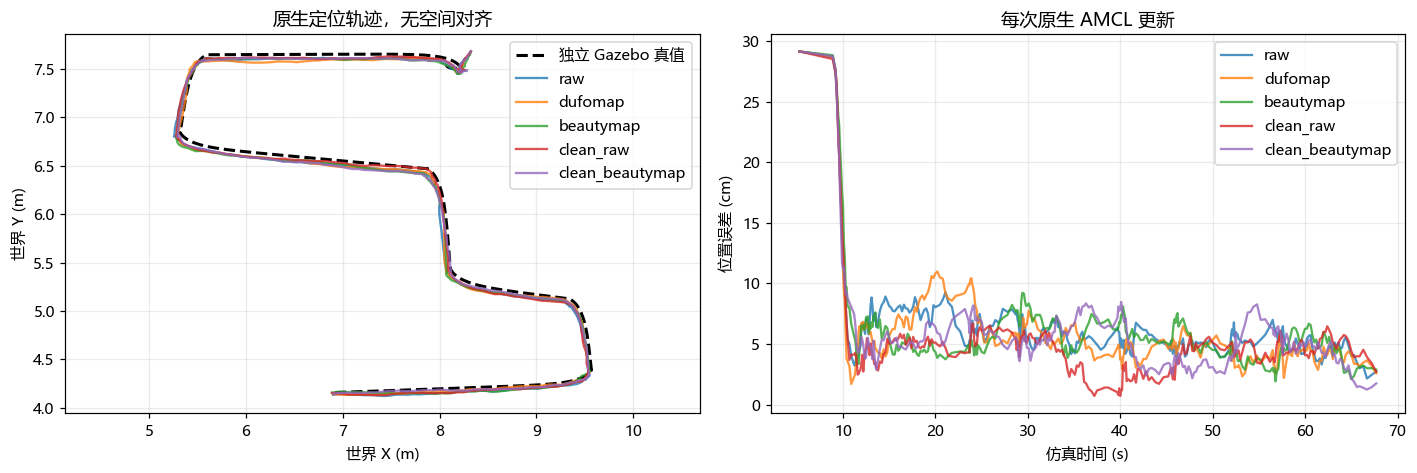

In [27]:
score_table("robot-dynamic")
trajectory_plot("robot-dynamic", ("raw", "dufomap", "beautymap", "clean_raw", "clean_beautymap"))

**观察**：动态地图三组全窗约 7.31 / 7.10 / 7.28 cm；静态地图同输入对照约 6.30 / 6.30 / 6.89 cm。它提示地图来源值得控制，但当前一次运行没有建立统计显著优势，也没有触发定位丢失。

**下一步**：固定地图、路线和初值，分别改变运动障碍密度、速度和遮挡持续时间，多次独立重复；观察失效阈值与是否需要恢复动作。

<a id="change"></a>
## 6. 实验 S3：持久结构变化

**实验问题**：历史静态地图遇到封闭通道、新墙和柱子，是否一定导致定位丢失？

**条件**：沿用静态 A 地图；B 世界增加稳定结构、封闭下方通道；定位参数与初值策略不变。它是地图失配实验，不是运动障碍密度实验。

In [28]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("localization-large-change", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\presentation.ps1 -Flow localization-large-change -RepoRoot D:\workspace\be2\slam_learning_updated -Duration 0


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

In [29]:
videos("robot-large-change")

地图 / 输入组,更新数,全窗 RMSE (cm),首条后 5s RMSE (cm),偏航 RMSE (°),位置 P95 (cm)
raw,290,6.250,6.022,1.115,7.957
dufomap,290,6.250,6.022,1.115,7.957
beautymap,290,6.156,5.923,1.071,8.359


由原生更新的估计与真值重新计算；最近真值时间差 ≤0.05 仿真秒；没有轨迹对齐。


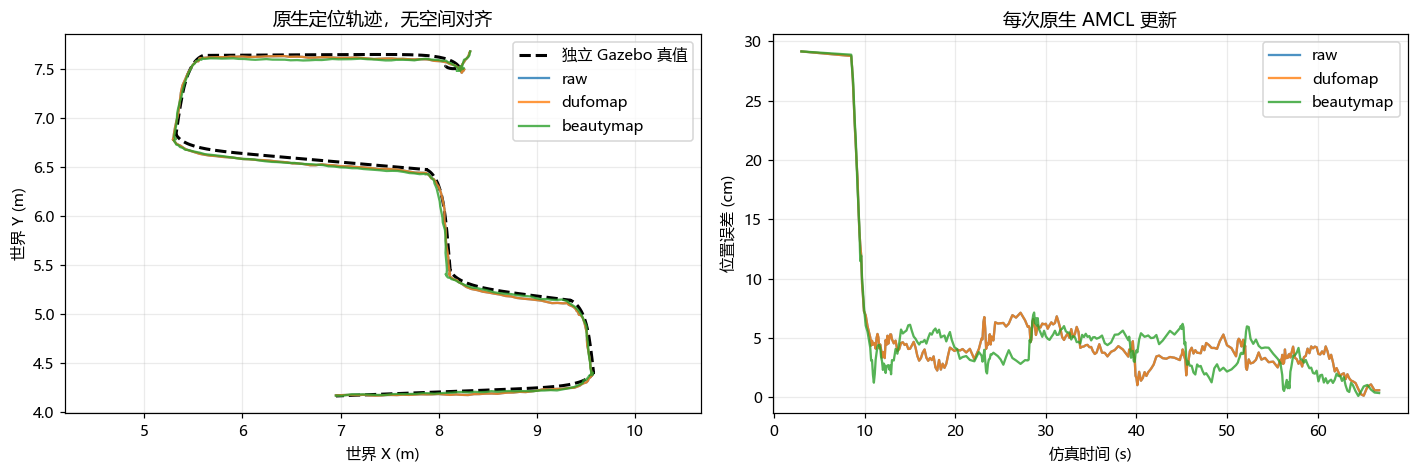

In [30]:
score_table("robot-large-change")
trajectory_plot("robot-large-change")

**观察**：本路线全窗约 6.25 / 6.25 / 6.16 cm，没有诱发失效。因此不能称作“大变化下自恢复成功”。没有失效事件，就无法评估恢复延迟。

**下一步**：控制变化面积、是否遮住主要稳定结构、进入变化区域的路线和初始不确定性，先产生可重复失效，再比较恢复策略；不能因为演示名叫“大变化”就假定难度已足够。

<a id="degradation"></a>
## 7. 实验 S4：走廊退化、受限观测与恢复

**实验问题**：在弱几何约束和有偏初值下，完整观测与受限观测的收敛差异有多大？恢复观测后，系统何时重新达到持续稳定的定位质量？

**条件**：两面 20 m 平行墙加端墙，A/B 地图几何相同。初值 X 偏差 1 m、Y 偏差 0.15 m、yaw 偏差 0.12 rad，故不能直接与其他场景的全窗误差排序。

| 对照 | 恢复前 | 恢复后 |
|---|---|---|
| 完整组三张地图 | 720 束 / 360° / 12 m | 保持完整 |
| 压力组三张地图 | 72 束 / 240° / 3.5 m | 恢复原始扫描 |

三维激光保持完整；没有人工扫描噪声。限束数、视角、距离是联合压力，尚未逐因素归因。恢复在录制开始后的 50 个**仿真秒**发生，保存事件时间戳为 t=58.6 s。机器人持续往返运动。

### 步骤 A：匹配走廊地图
三种最终二维地图一致；这本身是重要的控制信息。

In [31]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("mapping-corridor", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\presentation.ps1 -Flow mapping-corridor -RepoRoot D:\workspace\be2\slam_learning_updated -Duration 0


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

In [32]:
videos("robot-corridor-mapping", result=False)
mapping_info("robot-corridor-mapping")

项目,本轮记录
三维点云消息,808
保存建图帧,81
在线二维地图,401 × 59
已知栅格数,23288
三维建图位姿,给定的 Gazebo 传感器位姿；不是三维 SLAM 产出


In [33]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("build-corridor", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\build-maps.ps1 -Scene corridor -RepoRoot D:\workspace\be2\slam_learning_updated


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

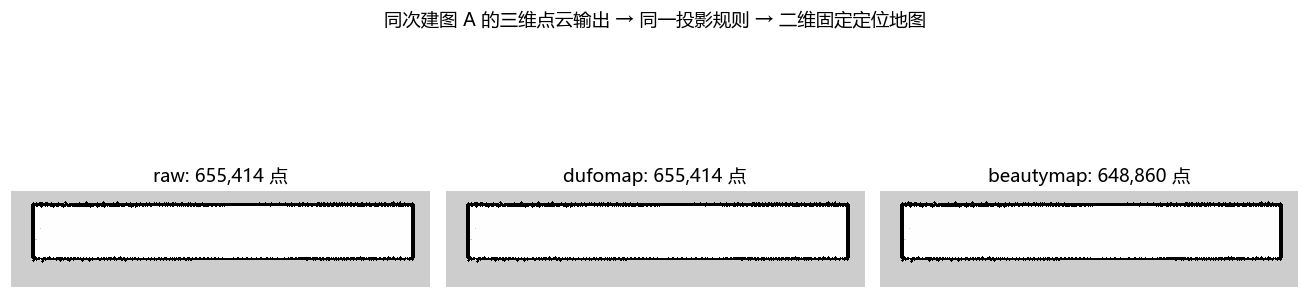

地图,输出点数,栅格 (m),PGM SHA-256 前16位
raw,655414,0.05,7647c46cb5ff8873
dufomap,655414,0.05,7647c46cb5ff8873
beautymap,648860,0.05,7647c46cb5ff8873


点数只是处理输出规模；没有逐点静动态真值，不能换算静态误删率。


In [34]:
map_comparison("robot-degradation")

### 步骤 B：现场自动压力流程
这一场启动采用自动往返，确保观测恢复后仍触发原生 AMCL 更新。手动测试可以改 `auto=False`，并保持运动；结束时用 `q`。

In [35]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("localization-degradation", enabled=START_THIS_EXPERIMENT, auto=True, record=False, duration=95)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\presentation.ps1 -Flow localization-degradation -RepoRoot D:\workspace\be2\slam_learning_updated -Duration 95 -Auto


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

In [36]:
videos("robot-degradation")

In [37]:
score_table("robot-degradation")

地图 / 输入组,更新数,全窗 RMSE (cm),首条后 5s RMSE (cm),偏航 RMSE (°),位置 P95 (cm)
raw,478,62.637,62.531,0.807,111.784
dufomap,478,62.637,62.531,0.807,111.784
beautymap,478,62.637,62.531,0.807,111.784
degraded_raw,478,73.631,73.562,0.815,108.104
degraded_dufomap,478,73.631,73.562,0.815,108.104
degraded_beautymap,478,73.631,73.562,0.815,108.104


由原生更新的估计与真值重新计算；最近真值时间差 ≤0.05 仿真秒；没有轨迹对齐。


### 步骤 C：不只看总 RMSE，检查事件前后与持续收敛

判据：位置误差 <0.1 m、绝对偏航差 <5°，保持至少 5 个仿真秒、至少 8 次原生更新。下面从保存的扫描事件和 CSV 找到第一个满足条件的窗口。

“11.3 秒恢复延迟”指稳定窗口的**起点**到扫描恢复的间隔；需要继续观察到窗口末端才可确认。不能将这个起点当作在线系统当时就知道已经恢复。

如果恢复后没有足够的新位姿更新，结论是证据不足；不能把缺少数据当成恢复失败。

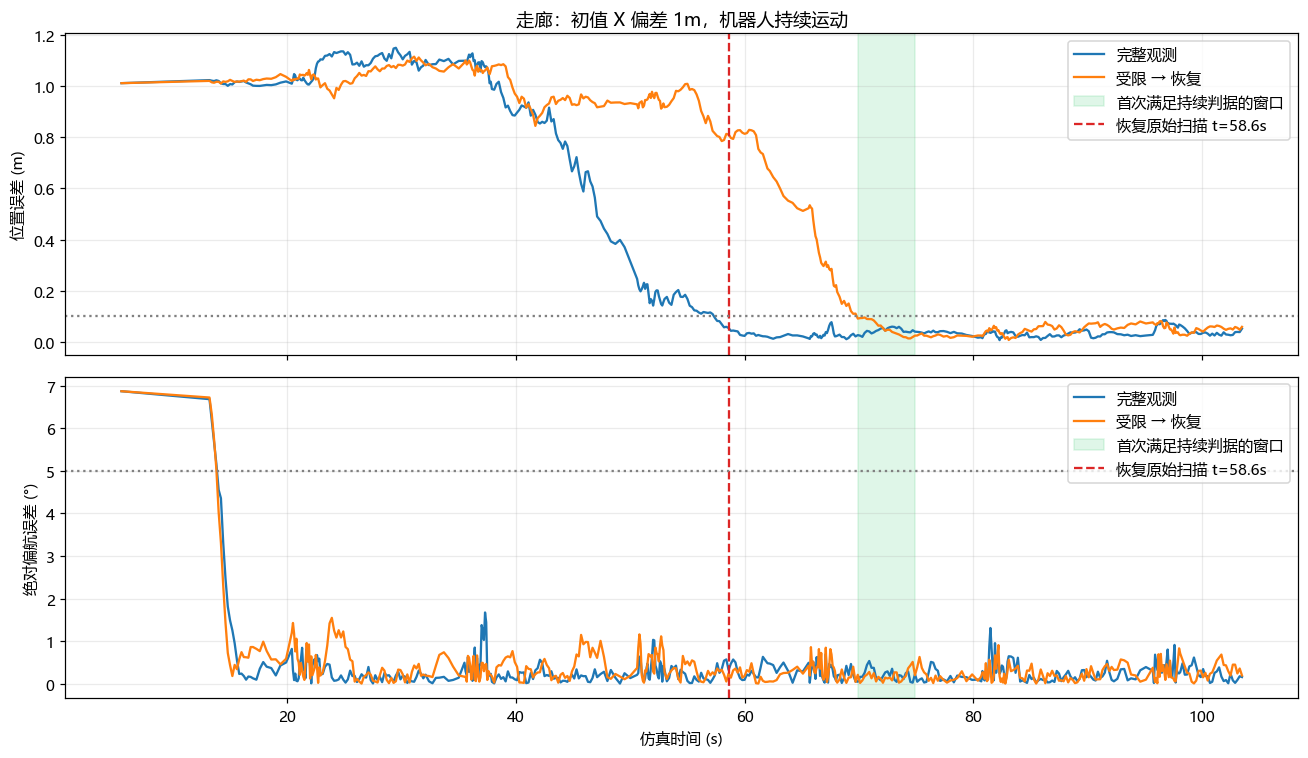

组,恢复前更新,恢复后更新,前 RMSE(m),后 RMSE(m),末误差(cm),稳定窗口起点延迟(s),可确认延迟(s),确认窗口更新数
完整观测,240,238,0.8831,0.0398,5.24,0.0,5.2,24
受限 → 恢复,240,238,1.0016,0.2778,5.94,11.3,16.3,26


实际扫描,扫描帧,法向小/大特征值比中位数
full_before,572,0.104199
limited,572,0.000242
restored,459,0.104831


11.3s 指首次稳定窗口的起点；必须观察到窗口末端才可确认。法向比仅为局部诊断。


In [38]:
degradation_analysis()

**观察**：压力组恢复前 RMSE 约 1.002 m，恢复后全阶段 0.278 m（包括过渡）；最后约 5.94 cm。首次持续稳定窗口约在恢复后 11.3 s 开始。完整组在事件前已基本收敛。

六组每组保留 478 次原生更新。三种地图一样、结果也一样，不能据此排名地图清理方法。扫描法向覆盖小/大特征值比从约 0.00024 返回约 0.1048；它是局部诊断，不是完整 SLAM Hessian，也不是经过校准的恢复概率。

**诊断经验**：首轮巡航提前结束，AMCL 因运动阈值不再生成新位姿，恢复之后没有评分记录。早先“恢复失败”解释已撤回；当前流程保持运动并检查更新覆盖。

**当前能回答**：受限扫描使有偏信念的收敛更困难，恢复扫描并继续运动后这次 AMCL 回到稳定误差范围。**暂不能回答**：自动检测 / 归因 / 选择恢复动作是否有效，实体绑架后是否恢复，三维 SLAM 是否恢复。

### 现场实验正常停止
先在专用终端按 `q`；如需脚本停止当前演示，可启用下面单元。不会用全局 kill 清理其他项目。新运行的日志在 `results/runs/presentation`，不要把未打包的新数据冒充这里的冻结结果。

In [39]:
# 单独启用这一场实验，再运行本单元。现场演示时先结束上一场。
START_THIS_EXPERIMENT = False
launch("stop", enabled=START_THIS_EXPERIMENT, auto=False, record=False, duration=90)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\stop-presentation.ps1 -RepoRoot D:\workspace\be2\slam_learning_updated


**现场启动单元尚未启用。** 需要现场演示时，把本单元 `START_THIS_EXPERIMENT` 改为 `True`，再单独运行；先结束上一场仿真。

<a id="narrow"></a>
## 8. 从结果收窄开放问题

**原问题有道理，但现在适合作为研究方向下的总问题。** 检测异常、区分退化与地图失配、选择恢复动作、确认恢复，不能靠单一 RMSE 全部回答。

我更愿意先收窄为一个可以实验验证的问题：

> **在已知二维地图的走廊定位中，短时观测受限与有偏位姿信念同时出现时，恢复观测后如何决定是否触发重新采样／重定位，并避免过早宣布恢复？**

固定底盘、Nav2 AMCL、地图与路线，首先检查“继续运动时自然恢复”和“停止时没有原生更新”的边界。这比同时涵盖所有退化和大变化更易控制；地图失配可作为随后扩展。这里是候选问题，不声称已经确定创新点。

| 下一轮因子 | 保持什么不变 | 什么结果会推翻判断 |
|---|---|---|
| 束数 / 视角 / 量程分别改变 | 地图、运动、初值 | 某一因子变化并不影响失效与恢复 |
| 初值偏移 0 / 0.25 / 1 m | 观测限制与运动 | 初值主导全部现象，不能归因退化 |
| 恢复后继续运动 / 停止 | 恢复时间、输入条件 | 有扫描但无新位姿时不能用旧误差宣布恢复 |
| 原生 AMCL / 触发式恢复候选 | 全部输入、评测窗口 | 候选降低平均误差却增加误触发或更慢恢复 |
| 静态地图 / 持久结构失配 | 同一路线与初值 | 失败机制不同，原退化策略无法外推 |

预先定义：失效事件、恢复预算、误触发率、恢复成功率、首次稳定窗口延迟、可确认延迟和计算负担。每种条件至少多次独立重复，并报告分布；不选择最好的一条录像作结论。

**向老师讨论**：先研究恢复触发和恢复确认，是否比同时设计检测、归因和重定位全部模块更适合当前能力？扫描约束诊断与原生位姿更新时间能否成为可解释的触发信号？

### 成果与边界

| 已完成 | 仍待做 |
|---|---|
| 四种作者代码流程的本机执行、成片与范围披露 | AdaM 完整数据 / 训练、其他论文完整协议 |
| 静态、动态、持久变化、走廊现场仿真与定位评分 | 固定各因子的多次重复与失效边界 |
| 同底盘二维定位 + 给定位姿的三维点云建图 | 原生三维 SLAM、逐点运动畸变、实体机器人 |
| 冻结 CSV/TUM、独立真值核对与指标更正 | 新自恢复策略及其可证伪对照 |

**收束讲述**：我现在希望先把实验事实和失效机制弄清楚，再选一个具体恢复边界做方法；即使当前方法尚未成功，能够解释限制和验证下一步也是这轮学习的成果。

## 9. 来源与便携文件

主库：[slam_learning_updated](https://github.com/p20030920p/slam_learning_updated)。每个冻结包的 `record.json` 保存来源运行目录、命令、参数与文件哈希；本 Notebook 不替换这些记录。

作者代码与论文出处请查库中的中英论文卡片 `docs/papers/{dufomap,beautymap,ir-mcl,adam-mcl}`；机器人和评分细节见 `docs/testing/LIVE.zh-CN.md`，问题分析见 `docs/self-recovery/DESIGN.zh-CN.md`。

本地目录内：`.ipynb` 可逐格运行；同名 `.html` 可离线播放视频和讲解；`evidence/` 为发布包副本；`experiment_tools.py` 为读取 / 复算 / 现场启动函数；`使用说明.md` 给出一键打开和现场操作。移动展示目录时保留这些文件的相对关系。

现场入口仍使用本机 `D:\workspace\be2\slam_learning_updated` 和已有 WSL 环境。将展示材料复制到其他电脑后，已保存结果与视频可用，现场重新实验需要重新配置对应环境。